In [1]:
import os
os.chdir(r"C:\TESI")
os.listdir()

['.Rhistory', 'Books.csv.gz', 'Books_5core', 'Books_test.jsonl']

In [2]:
import os
print("isdir:", os.path.isdir(r"C:\TESI\Books_test.jsonl"))
print("isfile:", os.path.isfile(r"C:\TESI\Books_test.jsonl"))

isdir: True
isfile: False


In [3]:
os.listdir(r"C:\TESI\Books_test.jsonl")[:20]

['.Rhistory', 'Books.jsonl']

In [4]:
import json

with open(r"C:\TESI\Books_test.jsonl\Books.jsonl", "r", encoding="utf-8") as f:
    row = json.loads(f.readline())

example = {
    "rating": row["rating"],
    "title": row["title"],
    "text": row["text"][:120] + "...",
    "user_id": row["user_id"],
    "parent_asin": row["parent_asin"],
    "timestamp": row["timestamp"]
}

print(json.dumps(example, indent=2))

{
  "rating": 1.0,
  "title": "Not a watercolor book! Seems like copies imo.",
  "text": "It is definitely not a watercolor book.  The paper bucked completely.  The pages honestly appear to be photo copies of o...",
  "user_id": "AFKZENTNBQ7A7V7UXW5JJI6UGRYQ",
  "parent_asin": "B09BGPFTDB",
  "timestamp": 1642399598485
}


In [5]:
!pip install duckdb pandas

In [6]:
import duckdb
import pandas as pd

con = duckdb.connect()

con.execute("""
SELECT rating, user_id, parent_asin
FROM read_json_auto('C:/TESI/Books_test.jsonl/Books.jsonl', format='newline_delimited')
LIMIT 5
""").df()

,rating,user_id,parent_asin
0,1.0,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,B09BGPFTDB
1,5.0,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,0593235657
2,5.0,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1782490671
3,5.0,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,0593138228
4,5.0,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,0823098079


## Numeri globali del dataset

In [7]:
raw_global = con.execute("""
SELECT
    COUNT(*) AS n_reviews,
    COUNT(DISTINCT user_id) AS n_users,
    COUNT(DISTINCT parent_asin) AS n_products
FROM read_json_auto(
    'C:/TESI/Books_test.jsonl/Books.jsonl',
    format='newline_delimited'
);
""").df()

raw_global

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,n_reviews,n_users,n_products
0,29475453,10297355,4446065


## Distribuzione numero di reviews per utente

In [8]:
con.execute("""
CREATE OR REPLACE TABLE user_review_counts AS
SELECT
    user_id,
    COUNT(*) AS n_reviews
FROM read_json_auto(
    'C:/TESI/Books_test.jsonl/Books.jsonl',
    format='newline_delimited'
)
GROUP BY user_id;
""")
user_stats = con.execute("""
SELECT
    COUNT(*) AS n_users,
    MIN(n_reviews) AS min_reviews,
    AVG(n_reviews) AS mean_reviews,
    APPROX_QUANTILE(n_reviews, 0.5) AS median,
    APPROX_QUANTILE(n_reviews, 0.9) AS p90,
    APPROX_QUANTILE(n_reviews, 0.99) AS p99,
    MAX(n_reviews) AS max_reviews
FROM user_review_counts;
""").df()

user_stats

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,n_users,min_reviews,mean_reviews,median,p90,p99,max_reviews
0,10297355,1,2.86243,1,5,24,3888


Dal dataset Books risultano 10.297.355 utenti.
La mediana è pari a 1: ciò significa che il 50% degli utenti ha scritto una sola review.
La media (2.86) è superiore alla mediana, indicando una distribuzione fortemente asimmetrica a destra (heavy-tailed).
Il 90% degli utenti ha scritto al massimo 5 review, mentre solo l'1% supera le 24 review.
Il numero massimo di review per utente è 3888, confermando la presenza di una coda lunga.

## Distribuzione del numero di reviews per prodotto

In [9]:
con.execute("""
CREATE OR REPLACE TABLE item_review_counts AS
SELECT
    parent_asin AS item,
    COUNT(*) AS n_reviews
FROM read_json_auto(
    'C:/TESI/Books_test.jsonl/Books.jsonl',
    format='newline_delimited'
)
GROUP BY parent_asin;
""")
item_stats = con.execute("""
SELECT
    COUNT(*) AS n_items,
    MIN(n_reviews) AS min_reviews,
    AVG(n_reviews) AS mean_reviews,
    APPROX_QUANTILE(n_reviews, 0.5) AS median,
    APPROX_QUANTILE(n_reviews, 0.9) AS p90,
    APPROX_QUANTILE(n_reviews, 0.99) AS p99,
    MAX(n_reviews) AS max_reviews
FROM item_review_counts;
""").df()

item_stats

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,n_items,min_reviews,mean_reviews,median,p90,p99,max_reviews
0,4446065,1,6.62956,2,11,78,42141


Nel dataset *Books* risultano 4.446.065 prodotti distinti.
La mediana del numero di reviews per prodotto è pari a 2: ciò significa che il 50% dei libri ha ricevuto al massimo due recensioni. Anche dal lato dei prodotti emerge quindi una forte sparsità del dataset.
La media è pari a 6.63, valore sensibilmente superiore alla mediana, indicando una distribuzione fortemente asimmetrica a destra (heavy-tailed). 
Il 90% dei prodotti ha al massimo 11 recensioni, mentre solo l’1% supera le 78 recensioni. Il numero massimo osservato è pari a 42.141 recensioni per un singolo prodotto, evidenziando la presenza di una coda estremamente lunga.
Confrontando questi risultati con la distribuzione delle reviews per utente, si osserva che i prodotti risultano ancora più sbilanciati: la differenza tra media e mediana è maggiore e la coda destra è significativamente più estesa (max 42.141 contro 3.888 per gli utenti). 
Questo suggerisce una forte concentrazione delle recensioni su un numero ristretto di libri, coerente con dinamiche tipiche dei mercati culturali (effetto bestseller), in cui pochi prodotti raccolgono la maggior parte dell’attenzione.

## Percentuale utenti con 1 sola review

In [10]:
one_review_users = con.execute("""
SELECT
    COUNT(*) * 100.0 / (SELECT COUNT(*) FROM user_review_counts) AS perc_one_review_users
FROM user_review_counts
WHERE n_reviews = 1;
""").df()

one_review_users

,perc_one_review_users
0,57.19324


## Percentuale prodotti con 1 sola review

In [11]:
one_review_items = con.execute("""
SELECT
    COUNT(*) * 100.0 / (SELECT COUNT(*) FROM item_review_counts) AS perc_one_review_items
FROM item_review_counts
WHERE n_reviews = 1;
""").df()

one_review_items

,perc_one_review_items
0,46.693155


## Percentuale delle review totali generata dal 10% degli utenti più attivi

In [12]:
pareto_users = con.execute("""
WITH ranked AS (
    SELECT
        n_reviews,
        ROW_NUMBER() OVER (ORDER BY n_reviews DESC) AS rn,
        COUNT(*) OVER () AS total_users
    FROM user_review_counts
),
top10 AS (
    SELECT SUM(n_reviews) AS top_reviews
    FROM ranked
    WHERE rn <= total_users * 0.10
)
SELECT
    top_reviews * 100.0 /
    (SELECT SUM(n_reviews) FROM user_review_counts) AS perc_reviews_top10_users
FROM top10;
""").df()

pareto_users

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,perc_reviews_top10_users
0,49.160388


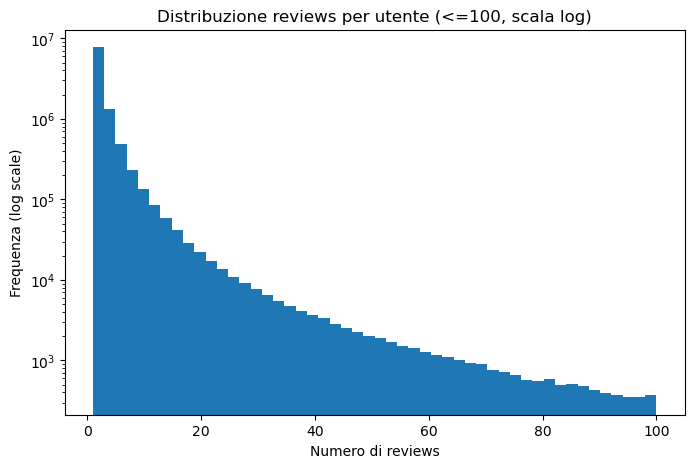

In [13]:
import matplotlib.pyplot as plt

user_data = con.execute("""
SELECT n_reviews
FROM user_review_counts
WHERE n_reviews <= 100
""").df()

plt.figure(figsize=(8,5))
plt.hist(user_data['n_reviews'], bins=50)
plt.yscale("log")
plt.title("Distribuzione reviews per utente (<=100, scala log)")
plt.xlabel("Numero di reviews")
plt.ylabel("Frequenza (log scale)")
plt.show()

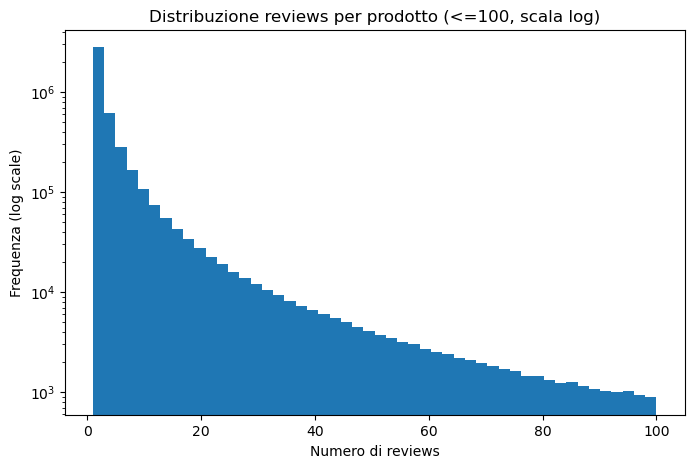

In [14]:
item_data = con.execute("""
SELECT n_reviews
FROM item_review_counts
WHERE n_reviews <= 100
""").df()
plt.figure(figsize=(8,5))
plt.hist(item_data['n_reviews'], bins=50)
plt.yscale("log")
plt.title("Distribuzione reviews per prodotto (<=100, scala log)")
plt.xlabel("Numero di reviews")
plt.ylabel("Frequenza (log scale)")
plt.show()

## Verifica missing rating

In [15]:
con.execute("""
SELECT COUNT(*) AS missing_rating
FROM read_json_auto(
    'C:/TESI/Books_test.jsonl/Books.jsonl',
    format='newline_delimited'
)
WHERE rating IS NULL;
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,missing_rating
0,0


## Verifica rating fuori range

In [16]:
con.execute("""
SELECT MIN(rating) AS min_rating,
       MAX(rating) AS max_rating
FROM read_json_auto(
    'C:/TESI/Books_test.jsonl/Books.jsonl',
    format='newline_delimited'
);
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,min_rating,max_rating
0,0.0,5.0


In [17]:
con.execute("""
SELECT COUNT(*) 
FROM read_json_auto(
    'C:/TESI/Books_test.jsonl/Books.jsonl',
    format='newline_delimited'
)
WHERE rating = 0;
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,count_star()
0,4


## Review senza testo

In [18]:
con.execute("""
SELECT COUNT(*) AS missing_text
FROM read_json_auto(
    'C:/TESI/Books_test.jsonl/Books.jsonl',
    format='newline_delimited'
)
WHERE text IS NULL OR LENGTH(TRIM(text)) = 0;
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,missing_text
0,7636


## user_id o prodotto mancanti

In [19]:
con.execute("""
SELECT 
    SUM(CASE WHEN user_id IS NULL THEN 1 ELSE 0 END) AS missing_user,
    SUM(CASE WHEN parent_asin IS NULL THEN 1 ELSE 0 END) AS missing_item
FROM read_json_auto(
    'C:/TESI/Books_test.jsonl/Books.jsonl',
    format='newline_delimited'
);
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,missing_user,missing_item
0,0.0,0.0


## Distribuzione delle classi di rating

In [20]:
rating_dist = con.execute("""
SELECT
    rating,
    COUNT(*) AS n,
    COUNT(*) * 100.0 / SUM(COUNT(*)) OVER() AS perc
FROM read_json_auto(
    'C:/TESI/Books_test.jsonl/Books.jsonl',
    format='newline_delimited'
)
WHERE rating >= 1
GROUP BY rating
ORDER BY rating;
""").df()

rating_dist

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,rating,n,perc
0,1.0,1316085,4.465021
1,2.0,1080897,3.667110
2,3.0,2054057,6.968705
3,4.0,4632932,15.717935
4,5.0,20391478,69.181229


## (1–2) vs 3 vs (4–5)

In [21]:
rating_grouped = con.execute("""
SELECT
    CASE
        WHEN rating IN (1,2) THEN 'negative'
        WHEN rating = 3 THEN 'neutral'
        WHEN rating IN (4,5) THEN 'positive'
    END AS class,
    COUNT(*) AS n,
    COUNT(*) * 100.0 / SUM(COUNT(*)) OVER() AS perc
FROM read_json_auto(
    'C:/TESI/Books_test.jsonl/Books.jsonl',
    format='newline_delimited'
)
WHERE rating >= 1
GROUP BY class;
""").df()

rating_grouped

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,class,n,perc
0,positive,25024410,84.899165
1,negative,2396982,8.132131
2,neutral,2054057,6.968705


## Lunghezza testi

In [22]:
text_length_stats = con.execute("""
SELECT
    AVG(LENGTH(text)) AS mean_length,
    APPROX_QUANTILE(LENGTH(text), 0.5) AS median_length,
    APPROX_QUANTILE(LENGTH(text), 0.9) AS p90,
    MAX(LENGTH(text)) AS max_length
FROM read_json_auto(
    'C:/TESI/Books_test.jsonl/Books.jsonl',
    format='newline_delimited'
)
WHERE text IS NOT NULL AND LENGTH(TRIM(text)) > 0;
""").df()

text_length_stats

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,mean_length,median_length,p90,max_length
0,423.185881,175,1054,37878


## Lunghezza vs rating

In [23]:
length_by_rating = con.execute("""
SELECT
    rating,
    AVG(LENGTH(text)) AS avg_length,
    APPROX_QUANTILE(LENGTH(text), 0.5) AS median_length
FROM read_json_auto(
    'C:/TESI/Books_test.jsonl/Books.jsonl',
    format='newline_delimited'
)
WHERE text IS NOT NULL AND LENGTH(TRIM(text)) > 0
GROUP BY rating
ORDER BY rating;
""").df()

length_by_rating

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,rating,avg_length,median_length
0,0.0,618.500000,440
1,1.0,456.367999,229
2,2.0,599.297668,301
3,3.0,614.114727,268
4,4.0,600.388669,244
5,5.0,352.209133,153


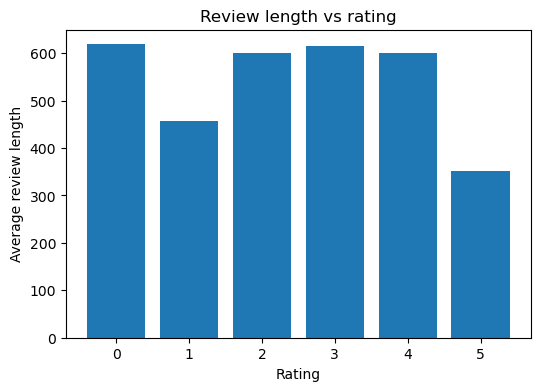

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

plt.bar(length_by_rating["rating"], length_by_rating["avg_length"])

plt.xlabel("Rating")
plt.ylabel("Average review length")
plt.title("Review length vs rating")

plt.show()

Recensioni a 5 stelle sono significativamente piu brevi

## Analisi dataset 5-core

In [25]:
import duckdb
con = duckdb.connect()

con.execute("""
CREATE OR REPLACE VIEW books_5core AS
SELECT *
FROM read_csv_auto('C:/TESI/Books.csv.gz');
""")
con.execute("SELECT COUNT(*) FROM books_5core").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,count_star()
0,9488297


## Numeri globali dataset

In [26]:
con.execute("""
SELECT
    COUNT(*) AS n_reviews,
    COUNT(DISTINCT user_id) AS n_users,
    COUNT(DISTINCT parent_asin) AS n_products
FROM books_5core
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,n_reviews,n_users,n_products
0,9488297,776370,495063


## Distribuzione review per utente

In [27]:
con.execute("""
CREATE OR REPLACE VIEW user_review_counts_5 AS
SELECT
    user_id,
    COUNT(*) AS n_reviews
FROM books_5core
GROUP BY user_id
""")
con.execute("""
SELECT
    COUNT(*) AS n_users,
    MIN(n_reviews) AS min_reviews,
    AVG(n_reviews) AS mean_reviews,
    APPROX_QUANTILE(n_reviews, 0.5) AS median,
    APPROX_QUANTILE(n_reviews, 0.9) AS p90,
    APPROX_QUANTILE(n_reviews, 0.99) AS p99,
    MAX(n_reviews) AS max_reviews
FROM user_review_counts_5
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,n_users,min_reviews,mean_reviews,median,p90,p99,max_reviews
0,776370,5,12.22136,7,20,87,3134


## Distribuzione review per prodotto

In [28]:
con.execute("""
CREATE OR REPLACE VIEW item_review_counts_5 AS
SELECT
    parent_asin,
    COUNT(*) AS n_reviews
FROM books_5core
GROUP BY parent_asin
""")
con.execute("""
SELECT
    COUNT(*) AS n_products,
    MIN(n_reviews) AS min_reviews,
    AVG(n_reviews) AS mean_reviews,
    APPROX_QUANTILE(n_reviews, 0.5) AS median,
    APPROX_QUANTILE(n_reviews, 0.9) AS p90,
    APPROX_QUANTILE(n_reviews, 0.99) AS p99,
    MAX(n_reviews) AS max_reviews
FROM item_review_counts_5
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,n_products,min_reviews,mean_reviews,median,p90,p99,max_reviews
0,495063,5,19.165837,9,34,166,12526


## Percentuale review generata dal 10% degli utenti più attivi

In [29]:
pareto_users_5 = con.execute("""
WITH ranked AS (
    SELECT
        n_reviews,
        ROW_NUMBER() OVER (ORDER BY n_reviews DESC) AS rn,
        COUNT(*) OVER () AS total_users
    FROM user_review_counts_5
),
top10 AS (
    SELECT SUM(n_reviews) AS top_reviews
    FROM ranked
    WHERE rn <= total_users * 0.10
)
SELECT
    top_reviews * 100.0 /
    (SELECT SUM(n_reviews) FROM user_review_counts_5) AS perc_reviews_top10_users
FROM top10;
""").df()

pareto_users_5

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,perc_reviews_top10_users
0,40.219789


## Distribuzione classi di rating

In [30]:
rating_dist_5 = con.execute("""
SELECT
    rating,
    COUNT(*) AS n,
    COUNT(*) * 100.0 / SUM(COUNT(*)) OVER() AS perc
FROM books_5core
GROUP BY rating
ORDER BY rating;
""").df()

rating_dist_5

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,rating,n,perc
0,1.0,274462,2.892637
1,2.0,356264,3.754773
2,3.0,818836,8.629958
3,4.0,1920017,20.235633
4,5.0,6118718,64.486999


## (1-2) vs 3 vs (4-5)

In [31]:
rating_grouped_5 = con.execute("""
SELECT
    CASE
        WHEN rating IN (1,2) THEN 'negative'
        WHEN rating = 3 THEN 'neutral'
        WHEN rating IN (4,5) THEN 'positive'
    END AS class,
    COUNT(*) AS n,
    COUNT(*) * 100.0 / SUM(COUNT(*)) OVER() AS perc
FROM books_5core
GROUP BY class
""").df()

rating_grouped_5

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,class,n,perc
0,positive,8038735,84.722633
1,negative,630726,6.647410
2,neutral,818836,8.629958


## Tabella confronto dimensioni dataset

In [32]:
import pandas as pd

compare_sizes = con.execute("""
WITH raw AS (
    SELECT
        COUNT(*) AS n_reviews,
        COUNT(DISTINCT user_id) AS n_users,
        COUNT(DISTINCT parent_asin) AS n_products
    FROM read_json_auto('C:/TESI/Books_test.jsonl/Books.jsonl', format='newline_delimited')
),
core AS (
    SELECT
        COUNT(*) AS n_reviews,
        COUNT(DISTINCT user_id) AS n_users,
        COUNT(DISTINCT parent_asin) AS n_products
    FROM books_5core
)
SELECT
    'n_reviews' AS metric, raw.n_reviews AS raw_value, core.n_reviews AS core_value
FROM raw, core
UNION ALL
SELECT
    'n_users', raw.n_users, core.n_users
FROM raw, core
UNION ALL
SELECT
    'n_products', raw.n_products, core.n_products
FROM raw, core
""").df()

compare_sizes["delta_abs"] = compare_sizes["core_value"] - compare_sizes["raw_value"]
compare_sizes["delta_pct"] = (compare_sizes["core_value"] / compare_sizes["raw_value"] - 1) * 100

compare_sizes

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,metric,raw_value,core_value,delta_abs,delta_pct
0,n_reviews,29475453,9488297,-19987156,-67.809496
1,n_users,10297355,776370,-9520985,-92.460491
2,n_products,4446065,495063,-3951002,-88.865143
